# Algoritmo de Manacher

Encuentra todos los palíndromos maximales de una cadena en $O(n)$. Para tratar igual los de longitud par e impar, se intercala un separador: `abba` pasa a ser `#a#b#b#a#`, donde todos tienen centro. Sea $d_i$ el radio del palíndromo más largo centrado en $i$ (que coincide con su longitud en la cadena original). Si $i$ cae dentro del palíndromo $[c - d_c,\ c + d_c]$ que llega más a la derecha ($r = c + d_c$), su simétrico $2c - i$ ya está calculado y

$$d_i \ge \min(d_{2c - i},\ r - i)$$

así que solo hay que seguir expandiendo desde ahí. Cada expansión con éxito hace avanzar $r$, que nunca retrocede, y el total es $O(n)$ frente a $O(n^2)$ de expandir desde cada centro.

## 1. Palíndromo más largo en O(n)

Implementar Manacher y devolver la subcadena palindrómica más larga. Mostrar los radios alineados bajo la cadena transformada y comprobarlo contra la fuerza bruta.

In [1]:
import random
import timeit

def manacher(s):
    t = "#" + "#".join(s) + "#"
    d, c, r = [0] * len(t), 0, 0
    for i in range(len(t)):
        if i < r:
            d[i] = min(d[2 * c - i], r - i)
        while i - d[i] > 0 and i + d[i] < len(t) - 1 and t[i - d[i] - 1] == t[i + d[i] + 1]:
            d[i] += 1
        if i + d[i] > r:
            c, r = i, i + d[i]
    return d

def palindromo_mas_largo(s):
    d = manacher(s)
    i = max(range(len(d)), key=d.__getitem__)
    inicio = (i - d[i]) // 2
    return s[inicio:inicio + d[i]]

def palindromo_bruto(s):
    n = len(s)
    return max((s[i:j] for i in range(n) for j in range(i, n + 1) if s[i:j] == s[i:j][::-1]), key=len, default="")

s = "abaaba"
t = "#" + "#".join(s) + "#"
print(" ".join(t))
print(" ".join(map(str, manacher(s))))
print(palindromo_mas_largo(s), palindromo_mas_largo("forgeeksskeegfor"))

random.seed(1)
for _ in range(1000):
    s = "".join(random.choices("ab", k=random.randint(0, 15)))
    assert len(palindromo_mas_largo(s)) == len(palindromo_bruto(s))
    assert palindromo_mas_largo(s) in s and palindromo_mas_largo(s) == palindromo_mas_largo(s)[::-1]

# a # b # a # a # b # a #
0 1 0 3 0 1 6 1 0 3 0 1 0
abaaba geeksskeeg


## 2. Expandir desde el centro

Resolver lo mismo expandiendo desde cada uno de los $2n - 1$ centros posibles, que cuesta $O(n^2)$ en el peor caso (por ejemplo, una cadena con todas las letras iguales). Comprobar que coincide con Manacher y comparar tiempos para tamaños crecientes en una gráfica.

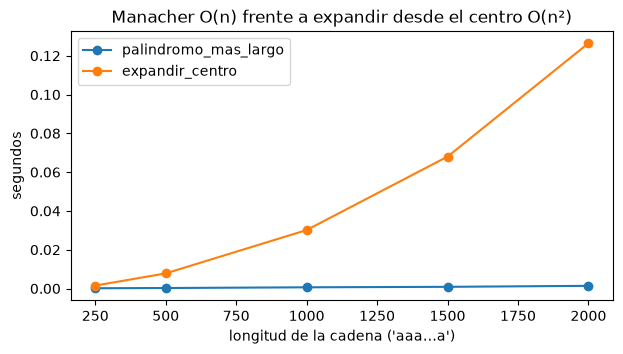

In [2]:
import matplotlib.pyplot as plt

def expandir_centro(s):
    mejor = (0, 0)
    for centro in range(2 * len(s) - 1):
        i, j = centro // 2, (centro + 1) // 2
        while i >= 0 and j < len(s) and s[i] == s[j]:
            i, j = i - 1, j + 1
        if j - i - 1 > mejor[1] - mejor[0]:
            mejor = (i + 1, j)
    return s[mejor[0]:mejor[1]]

for _ in range(1000):
    s = "".join(random.choices("ab", k=random.randint(0, 15)))
    assert len(expandir_centro(s)) == len(palindromo_mas_largo(s))

longitudes = [250, 500, 1000, 1500, 2000]
tiempos = {f: [] for f in (palindromo_mas_largo, expandir_centro)}
for n in longitudes:
    s = "a" * n
    for f, lista in tiempos.items():
        lista.append(timeit.timeit(lambda: f(s), number=1))

fig, eje = plt.subplots(figsize=(7, 3.5))
for f, lista in tiempos.items():
    eje.plot(longitudes, lista, marker="o", label=f.__name__)
eje.set_xlabel("longitud de la cadena ('aaa…a')")
eje.set_ylabel("segundos")
eje.set_title("Manacher O(n) frente a expandir desde el centro O(n²)")
eje.legend()
plt.show()

## 3. Contar subcadenas palindrómicas

Contar cuántas subcadenas (por posición) son palíndromos. Un centro de la cadena transformada con radio $d_i$ contiene los palíndromos de longitudes $d_i, d_i - 2, \dots$ hasta 1 o 2, que son $\lceil d_i / 2 \rceil$; sumándolos sale el total en $O(n)$. Comprobarlo con fuerza bruta.

In [3]:
def cuenta_palindromos(s):
    return sum((d + 1) // 2 for d in manacher(s))

def cuenta_palindromos_bruto(s):
    return sum(s[i:j] == s[i:j][::-1] for i in range(len(s)) for j in range(i + 1, len(s) + 1))

for _ in range(1000):
    s = "".join(random.choices("abc", k=random.randint(0, 15)))
    assert cuenta_palindromos(s) == cuenta_palindromos_bruto(s)
print(cuenta_palindromos("abc"), cuenta_palindromos("aaa"), cuenta_palindromos("abba"))

3 6 6


## 4. Palíndromo más corto añadiendo por delante

Calcular el palíndromo más corto que se obtiene añadiendo caracteres al principio de una cadena. Basta con encontrar su prefijo palindrómico más largo y añadir delante el resto invertido. Con los radios de Manacher, el centro $i$ alcanza el principio de la cadena cuando $i = d_i$. Comprobarlo con fuerza bruta.

In [4]:
def palindromo_mas_corto(s):
    prefijo = max(d for i, d in enumerate(manacher(s)) if i == d)
    return s[prefijo:][::-1] + s

def palindromo_mas_corto_bruto(s):
    prefijo = max(k for k in range(len(s) + 1) if s[:k] == s[:k][::-1])
    return s[prefijo:][::-1] + s

for _ in range(1000):
    s = "".join(random.choices("ab", k=random.randint(0, 12)))
    assert palindromo_mas_corto(s) == palindromo_mas_corto_bruto(s)
print(palindromo_mas_corto("aacecaaa"), palindromo_mas_corto("abcd"), palindromo_mas_corto("reconocer"))

aaacecaaa dcbabcd reconocer
